# Phân tích chuỗi PM2.5 theo Chương 12

Notebook này làm theo pipeline của Chương 12 (*Hands-On Artificial Intelligence for IoT*), áp dụng cho PM2.5 trung bình giờ:

1. Chuỗi giờ và trung bình trượt 24 giờ để xem trend
2. Khử trend bằng `diff()`
3. ACF, ghi nhận có đỉnh ở lag 24 hay không
4. Khử seasonality bằng sai phân lag 24
5. Kiểm định ADF trước và sau khi khử
6. Chuẩn bị dữ liệu cho LSTM: chia theo thời gian, `MinMaxScaler` chỉ fit trên train, cửa sổ 24 giờ → 6 giờ

**Dữ liệu dùng ở đây:** dữ liệu của trạm trên Pi hiện còn quá ngắn (mới vài ngày), chưa đủ để phân tích chu kỳ ngày hay huấn luyện. Vì vậy notebook dùng dữ liệu công khai cho Hà Nội từ Open-Meteo (`training/data/hanoi_openmeteo.csv`, nguồn ghi trong `training/data/SOURCE.md`). Giá trị PM2.5/PM10 ở đây là **đầu ra mô hình CAMS**, không phải số đo của trạm quan trắc, nên chỉ dùng để huấn luyện sơ bộ (cold start). Khi trạm đã có đủ dữ liệu, chạy lại notebook với file từ `training/export_hourly.py`.

Notebook không dùng lại hàm `normalize()` của notebook gốc Chương 12, vì hàm đó fit `MinMaxScaler` trên toàn chuỗi (rò rỉ thông tin tập test). Các hàm chuẩn bị dữ liệu nằm ở `training/data.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf, adfuller

# Chạy được cả khi thư mục làm việc là gốc repo hoặc training/
ROOT = Path.cwd() if (Path.cwd() / "training").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from training.data import (add_time_features, chrono_split, difference, fit_scaler,
                           make_windows)

plt.rcParams.update({"figure.dpi": 72, "figure.figsize": (11, 3.5), "axes.grid": True})

DATA = ROOT / "training" / "data" / "hanoi_openmeteo.csv"
df = pd.read_csv(DATA, parse_dates=["timestamp"])
df = df.set_index(pd.DatetimeIndex(df["timestamp"]).tz_convert("Asia/Ho_Chi_Minh")).drop(columns="timestamp")
full = pd.date_range(df.index[0], df.index[-1], freq="h")
print(f"Khoảng thời gian: {df.index[0]} .. {df.index[-1]}")
print(f"Số giờ: {len(df)} / {len(full)} giờ trên lưới đều; giờ thiếu pm25: {int(df['pm25'].isna().sum()) + len(full) - len(df)}")
df = df.reindex(full)
pm25 = df["pm25"]
df.describe().round(1)

Khoảng thời gian: 2022-08-04 07:00:00+07:00 .. 2026-11-06 23:00:00+07:00
Số giờ: 37337 / 37337 giờ trên lưới đều; giờ thiếu pm25: 0


,pm25,pm10,temp,hum,wind,precip
count,37337.0,37337.0,37337.0,37337.0,37337.0,37337.0
mean,45.2,55.9,24.6,79.1,9.0,0.3
std,27.8,33.2,5.4,14.7,4.6,1.1
min,0.3,0.4,6.7,21.0,0.0,0.0
25%,26.0,32.8,21.2,69.0,5.5,0.0
50%,38.1,47.4,25.5,82.0,8.5,0.0
75%,56.3,70.3,28.3,92.0,12.0,0.1
max,232.8,291.5,40.2,100.0,62.4,28.8


## 1. Chuỗi giờ và trung bình trượt 24 giờ

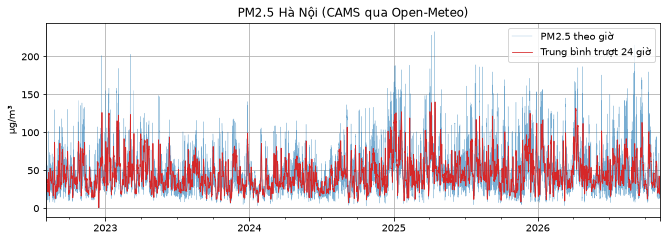

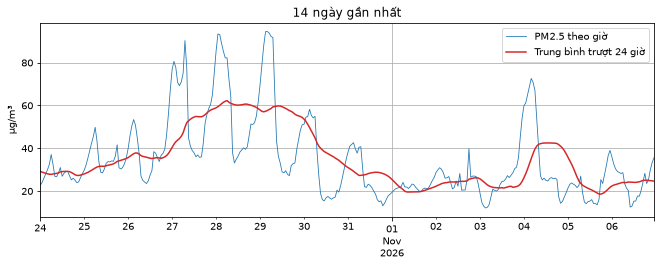

TB theo tháng (µg/m³): {1: 53.4, 2: 41.6, 3: 46.0, 4: 58.0, 5: 40.3, 6: 40.8, 7: 42.8, 8: 45.8, 9: 44.1, 10: 40.3, 11: 42.2, 12: 49.0}
TB theo giờ trong ngày (µg/m³): {0: 53.1, 1: 51.3, 2: 49.7, 3: 48.3, 4: 47.2, 5: 46.2, 6: 46.5, 7: 46.3, 8: 42.2, 9: 37.6, 10: 35.1, 11: 34.6, 12: 35.0, 13: 35.7, 14: 36.2, 15: 36.5, 16: 37.0, 17: 40.1, 18: 47.0, 19: 54.4, 20: 56.8, 21: 56.8, 22: 56.7, 23: 55.5}
Giờ cao nhất trong ngày: 20h (56.8), thấp nhất: 11h (34.6)


In [2]:
roll24 = pm25.rolling(24).mean()
fig, ax = plt.subplots()
pm25.plot(ax=ax, lw=0.3, alpha=0.6, label="PM2.5 theo giờ")
roll24.plot(ax=ax, lw=0.8, color="C3", label="Trung bình trượt 24 giờ")
ax.set_ylabel("µg/m³"); ax.set_title("PM2.5 Hà Nội (CAMS qua Open-Meteo)"); ax.legend(loc="upper right")
plt.show()

# Phóng to 14 ngày gần nhất để thấy dao động trong ngày
last = pm25.iloc[-14 * 24:]
fig, ax = plt.subplots()
last.plot(ax=ax, lw=0.8, label="PM2.5 theo giờ")
roll24.iloc[-14 * 24:].plot(ax=ax, color="C3", label="Trung bình trượt 24 giờ")
ax.set_ylabel("µg/m³"); ax.set_title("14 ngày gần nhất"); ax.legend(loc="upper right")
plt.show()

monthly = pm25.groupby(pm25.index.month).mean().round(1)
hourly_profile = pm25.groupby(pm25.index.hour).mean().round(1)
print("TB theo tháng (µg/m³):", monthly.to_dict())
print("TB theo giờ trong ngày (µg/m³):", hourly_profile.to_dict())
print(f"Giờ cao nhất trong ngày: {hourly_profile.idxmax()}h ({hourly_profile.max()}), thấp nhất: {hourly_profile.idxmin()}h ({hourly_profile.min()})")

**Nhận xét bước 1 (từ kết quả ở trên):**

- Dữ liệu từ 04/08/2022 07:00 đến 06/11/2026 23:00, 37 337 giờ liên tục, không thiếu giờ nào (đây là dữ liệu mô hình nên không bị mất mẫu như cảm biến thật).
- Trung bình trượt 24 giờ dao động mạnh giữa khoảng 1 và 140 µg/m³; không thấy trend tăng hay giảm đều qua các năm, mà là các đợt ô nhiễm kéo dài nhiều ngày, dày hơn vào mùa khô (TB tháng 1 là 53,4, tháng 12 là 49,0 µg/m³; tháng 4 cao nhất với 58,0 µg/m³, còn tháng 5 và tháng 10 thấp nhất, 40,3 µg/m³).
- Có chu kỳ ngày rõ: TB theo giờ thấp nhất lúc 11h (34,6 µg/m³) và cao nhất lúc 20–21h (56,8 µg/m³), tức buổi tối cao hơn buổi trưa khoảng 22 µg/m³. Đây là lý do kỳ vọng đỉnh ACF ở lag 24.

## 2. Khử trend bằng `diff()`

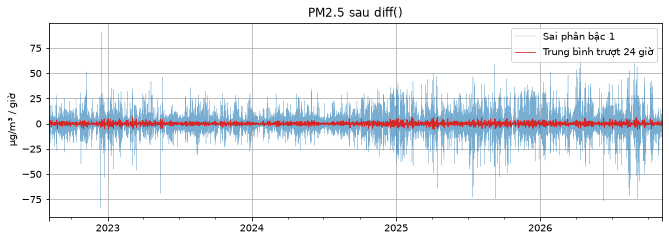

TB trượt 24 giờ của chuỗi gốc: min 0.7, max 140.1
TB trượt 24 giờ sau diff():   min -6.45, max 6.83


In [3]:
fod = pm25.diff()
fig, ax = plt.subplots()
fod.plot(ax=ax, lw=0.3, alpha=0.6, label="Sai phân bậc 1")
fod.rolling(24).mean().plot(ax=ax, color="C3", lw=0.8, label="Trung bình trượt 24 giờ")
ax.set_ylabel("µg/m³ / giờ"); ax.set_title("PM2.5 sau diff()"); ax.legend(loc="upper right")
plt.show()
print(f"TB trượt 24 giờ của chuỗi gốc: min {roll24.min():.1f}, max {roll24.max():.1f}")
print(f"TB trượt 24 giờ sau diff():   min {fod.rolling(24).mean().min():.2f}, max {fod.rolling(24).mean().max():.2f}")

**Nhận xét bước 2:** sau `diff()`, trung bình trượt 24 giờ chỉ còn trong khoảng −6,45 đến 6,83 µg/m³/giờ và dao động quanh 0, so với 0,7–140,1 µg/m³ của chuỗi gốc. Mức nền thay đổi theo đợt (phần trend cục bộ) đã bị loại; phần còn lại chủ yếu là biến động giờ sang giờ.

## 3. ACF: có đỉnh ở lag 24 không?

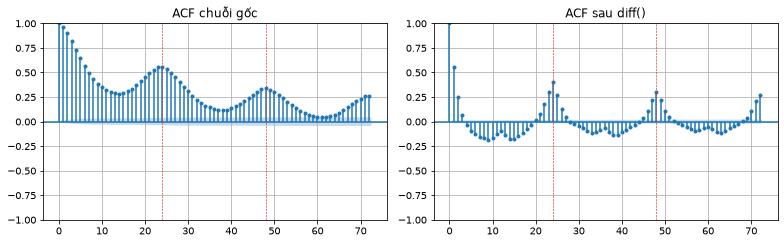

Chuỗi gốc: acf[1]=0.968 acf[12]=0.303 acf[23]=0.551 acf[24]=0.556 acf[25]=0.536 acf[48]=0.338
   cực đại địa phương: [24, 48]; lag có ACF lớn nhất trong 12..36: 24
Sau diff(): acf[1]=0.553 acf[12]=-0.093 acf[23]=0.302 acf[24]=0.404 acf[25]=0.269 acf[48]=0.305
   cực đại địa phương: [12, 24, 36, 48, 60]; lag có ACF lớn nhất trong 12..36: 24


In [4]:
LAGS = 72
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
plot_acf(pm25.dropna(), lags=LAGS, ax=axes[0], title="ACF chuỗi gốc", markersize=3)
plot_acf(fod.dropna(), lags=LAGS, ax=axes[1], title="ACF sau diff()", markersize=3)
for a in axes:
    for k in (24, 48):
        a.axvline(k, color="C3", lw=0.6, ls="--")
plt.tight_layout(); plt.show()

def acf_peak_report(series, name, lags=LAGS):
    r = acf(series.dropna(), nlags=lags)
    local_max = [k for k in range(2, lags) if r[k] > r[k - 1] and r[k] > r[k + 1]]
    top = max(range(12, 37), key=lambda k: r[k])   # lag lớn nhất trong khoảng 12..36
    print(f"{name}: acf[1]={r[1]:.3f} acf[12]={r[12]:.3f} acf[23]={r[23]:.3f} acf[24]={r[24]:.3f} "
          f"acf[25]={r[25]:.3f} acf[48]={r[48]:.3f}")
    print(f"   cực đại địa phương: {local_max}; lag có ACF lớn nhất trong 12..36: {top}")
    return r

r_raw = acf_peak_report(pm25, "Chuỗi gốc")
r_fod = acf_peak_report(fod, "Sau diff()")

**Nhận xét bước 3 — có đỉnh ở lag 24 như kỳ vọng:**

- Chuỗi gốc: ACF giảm dần từ 0,968 (lag 1) xuống 0,303 (lag 12) rồi tăng lại thành cực đại địa phương ở **lag 24 (0,556)**, lặp lại ở lag 48 (0,338). Đây là chu kỳ ngày; ACF giảm chậm cũng cho thấy chuỗi có tính nhớ dài.
- Sau `diff()`: đỉnh lag 24 còn rõ hơn so với lân cận (acf[23] = 0,302, **acf[24] = 0,404**, acf[25] = 0,269), lặp lại ở lag 48 (0,305). Lag 24 là lag có ACF lớn nhất trong khoảng 12–36 ở cả hai chuỗi.
- Hàm tìm cực đại còn báo lag 12, 36, 60 cho chuỗi sau `diff()`, nhưng giá trị ở đó rất nhỏ (acf[12] = −0,093), chỉ là gợn nhỏ, không phải chu kỳ 12 giờ đáng kể.

Vậy cần khử thêm seasonality theo ngày bằng sai phân lag 24.

## 4. Khử seasonality bằng sai phân lag 24

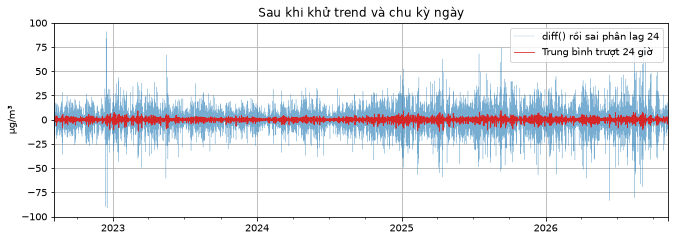

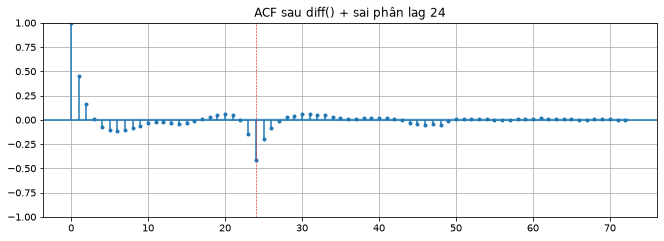

diff() + lag 24: acf[1]=0.448 acf[12]=-0.024 acf[23]=-0.145 acf[24]=-0.417 acf[25]=-0.197 acf[48]=-0.057
   cực đại địa phương: [12, 20, 31, 40, 47, 51, 53, 58, 61, 64, 68, 70]; lag có ACF lớn nhất trong 12..36: 20


In [5]:
# Sai phân lag 24 áp lên chuỗi đã diff() (khử cả trend và chu kỳ ngày),
# và để so sánh, sai phân lag 24 áp thẳng lên chuỗi gốc
d1_24 = difference(fod, 24)
d24 = difference(pm25, 24)

fig, ax = plt.subplots()
d1_24.plot(ax=ax, lw=0.3, alpha=0.6, label="diff() rồi sai phân lag 24")
d1_24.rolling(24).mean().plot(ax=ax, color="C3", lw=0.8, label="Trung bình trượt 24 giờ")
ax.set_ylabel("µg/m³"); ax.legend(loc="upper right"); ax.set_title("Sau khi khử trend và chu kỳ ngày")
plt.show()

fig, ax = plt.subplots()
plot_acf(d1_24.dropna(), lags=LAGS, ax=ax, title="ACF sau diff() + sai phân lag 24", markersize=3)
ax.axvline(24, color="C3", lw=0.6, ls="--")
plt.show()
r_d1_24 = acf_peak_report(d1_24, "diff() + lag 24")

**Nhận xét bước 4:** sau `diff()` rồi sai phân lag 24, đỉnh dương ở lag 24 không còn. Thay vào đó ACF tại lag 24 là **−0,417** (âm mạnh), lag 48 chỉ còn −0,057, và lag có ACF lớn nhất trong 12–36 chuyển sang lag 20. ACF âm mạnh đúng tại lag 24 là dấu hiệu quen thuộc của sai phân mùa: chu kỳ ngày đã bị khử, nhưng sai phân lag 24 cũng tạo ra tương quan âm (có thể đang khử quá tay). Nếu dùng mô hình kiểu SARIMA trên chuỗi này thì cần thành phần MA mùa ở lag 24; LSTM thì vẫn học trên chuỗi gốc đã chuẩn hoá, kèm đặc trưng sin/cos giờ.

## 5. Kiểm định ADF trước và sau khi khử

In [6]:
def adf_row(series, name):
    stat, p, used, nobs, crit, _ = adfuller(series.dropna(), autolag="AIC", result_object=False)
    return {"chuỗi": name, "ADF": round(stat, 3), "p-value": float(f"{p:.3g}"), "số lag": used,
            "số quan sát": nobs, "ngưỡng 1%": round(crit["1%"], 3), "ngưỡng 5%": round(crit["5%"], 3)}

adf_table = pd.DataFrame([
    adf_row(pm25, "gốc"),
    adf_row(fod, "diff()"),
    adf_row(d24, "sai phân lag 24"),
    adf_row(d1_24, "diff() + lag 24"),
]).set_index("chuỗi")
adf_table

,ADF,p-value,số lag,số quan sát,ngưỡng 1%,ngưỡng 5%
chuỗi,,,,,,
gốc,-17.916,2.920000e-30,50,37286,-3.431,-2.862
diff(),-33.826,0.000000e+00,53,37282,-3.431,-2.862
sai phân lag 24,-30.761,0.000000e+00,49,37263,-3.431,-2.862
diff() + lag 24,-44.250,0.000000e+00,53,37258,-3.431,-2.862


In [7]:
# ADF trên một năm gần nhất của chuỗi gốc: kiểm tra kết luận có phụ thuộc độ dài chuỗi không
pd.DataFrame([adf_row(pm25.iloc[-365 * 24:], "gốc, 1 năm gần nhất"),
              adf_row(pm25.iloc[-60 * 24:], "gốc, 60 ngày gần nhất")]).set_index("chuỗi")

,ADF,p-value,số lag,số quan sát,ngưỡng 1%,ngưỡng 5%
chuỗi,,,,,,
"gốc, 1 năm gần nhất",-9.509,3.290000e-16,37,8722,-3.431,-2.862
"gốc, 60 ngày gần nhất",-3.077,2.830000e-02,24,1415,-3.435,-2.864


**Nhận xét bước 5 — ADF (giả thuyết H0: chuỗi có nghiệm đơn vị, không dừng):**

| Chuỗi | ADF | p-value |
| --- | --- | --- |
| gốc | −17,916 | 2,92·10⁻³⁰ |
| `diff()` | −33,826 | ≈ 0 (nhỏ hơn độ chính xác máy, in ra 0) |
| sai phân lag 24 | −30,761 | ≈ 0 |
| `diff()` + lag 24 | −44,250 | ≈ 0 |

- Kết quả **khác với kỳ vọng trong sách:** ngay chuỗi gốc đã bác bỏ H0 rất mạnh (ADF −17,9 so với ngưỡng 1% là −3,431), tức theo ADF chuỗi PM2.5 giờ của Hà Nội đã dừng trước khi khử. PM2.5 dao động quanh một mức nền và quay về sau mỗi đợt ô nhiễm, không trôi như giá cổ phiếu trong ví dụ Chương 12.
- Sau khi khử, thống kê ADF âm hơn nữa (−33,8 và −44,3), p-value về 0; sai phân không làm hỏng tính dừng nhưng cũng không cần thiết để đạt tính dừng theo ADF.
- Với chuỗi ngắn hơn, kết luận yếu dần: 1 năm gần nhất ADF −9,509 (p = 3,29·10⁻¹⁶), 60 ngày gần nhất ADF −3,077 (p = 0,0283) — vẫn bác bỏ H0 ở mức 5% nhưng không ở mức 1% (ngưỡng −3,435). Kiểm định ADF trên chuỗi rất dài có độ nhạy cao, nên khi trạm mới có vài tuần dữ liệu thì cần chạy lại và đọc kết quả thận trọng.
- Lưu ý: ADF không kiểm tra seasonality; chu kỳ ngày vẫn thấy rõ trong ACF ở bước 3 dù ADF đã báo dừng.

## 6. Chuẩn bị dữ liệu cho LSTM

Dùng các hàm trong `training/data.py`: thêm sin/cos giờ trong ngày, chia 70/15/15 theo thời gian (không xáo trộn), fit `MinMaxScaler` **chỉ trên tập train**, rồi tạo cửa sổ 24 giờ → 6 giờ. Cửa sổ nào chạm giờ thiếu thì bị bỏ.

In [8]:
FEATURES = ["pm25", "temp", "hum", "hour_sin", "hour_cos"]
data = add_time_features(df)[FEATURES]
train, val, test = chrono_split(data, train=0.7, val=0.15)
for name, part in (("train", train), ("val", val), ("test", test)):
    print(f"{name:5s}: {part.index[0]} .. {part.index[-1]}  ({len(part)} giờ, PM2.5 max {part['pm25'].max():.1f})")

scaler = fit_scaler(train, FEATURES)
print("Scaler fit trên train: pm25 min/max =", scaler.data_min_[0], "/", scaler.data_max_[0])

windows = {name: make_windows(part, target="pm25", n_in=24, n_out=6, scaler=scaler)
           for name, part in (("train", train), ("val", val), ("test", test))}
for name, (X, y, t) in windows.items():
    print(f"{name:5s}: X {X.shape}, y {y.shape}, giờ đích đầu tiên {t[0]}")

train: 2022-08-04 07:00:00+07:00 .. 2025-07-28 06:00:00+07:00  (26136 giờ, PM2.5 max 232.8)
val  : 2025-07-28 07:00:00+07:00 .. 2026-03-18 15:00:00+07:00  (5601 giờ, PM2.5 max 186.3)
test : 2026-03-18 16:00:00+07:00 .. 2026-11-06 23:00:00+07:00  (5600 giờ, PM2.5 max 215.1)
Scaler fit trên train: pm25 min/max = 0.3 / 232.8
train: X (26107, 24, 5), y (26107, 6), giờ đích đầu tiên 2022-08-05 07:00:00+07:00
val  : X (5572, 24, 5), y (5572, 6), giờ đích đầu tiên 2025-07-29 07:00:00+07:00
test : X (5571, 24, 5), y (5571, 6), giờ đích đầu tiên 2026-03-19 16:00:00+07:00


**Nhận xét bước 6:** chia theo thời gian được train 04/08/2022–28/07/2025 (26 136 giờ), val đến 18/03/2026 (5 601 giờ), test đến 06/11/2026 (5 600 giờ), không chồng lấn. Scaler fit trên train có max PM2.5 = 232,8 µg/m³; val (186,3) và test (215,1) đều nằm trong khoảng này nên giá trị chuẩn hoá không vượt 1, nhưng với dữ liệu trạm thật thì có thể vượt và cần chấp nhận điều đó thay vì fit lại trên toàn chuỗi. Số cửa sổ 24 → 6: train 26 107, val 5 572, test 5 571 (mỗi tập mất 29 cửa sổ ở biên vì cửa sổ không vượt qua ranh giới tập).

## Kết luận

- Có chu kỳ ngày rõ ràng: ACF có đỉnh tại lag 24 (và 48) ở cả chuỗi gốc lẫn chuỗi sau `diff()`; PM2.5 trung bình cao nhất lúc 20–21h, thấp nhất lúc 11h. Điều này ủng hộ dùng cửa sổ đầu vào 24 giờ và đặc trưng sin/cos giờ, đồng thời cho thấy mô hình đối chứng seasonal naive (cùng giờ hôm qua) là đối chứng có ý nghĩa.
- ADF bác bỏ nghiệm đơn vị ngay trên chuỗi gốc (p = 2,92·10⁻³⁰), nên với dữ liệu này việc sai phân không bắt buộc để đạt tính dừng; sai phân lag 24 khử được đỉnh mùa nhưng để lại ACF âm mạnh ở lag 24.
- Hạn chế: đây là **dữ liệu mô hình CAMS** (lưới thô, mỗi ô cỡ hàng chục km), không phải số đo của trạm hay của cảm biến PMS7003 trong nhà. Mức tuyệt đối và biên độ trong ngày có thể khác dữ liệu thật; chỉ dùng để huấn luyện sơ bộ (cold start), sau đó tinh chỉnh và đánh giá lại trên dữ liệu của trạm khi đã đủ dài.
- Dữ liệu của Pi hiện mới vài ngày, quá ngắn để phân tích lại; khi đủ (ít nhất vài tuần), xuất bằng `python training/export_hourly.py --db aiot.db --out hourly.csv` và chạy lại notebook với file đó.